<a href="https://colab.research.google.com/github/Jesus-0655/Entregable_3_Aprendizaje_Entrenamiento_Dataset/blob/main/Modelo_Entrenado_Baterias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Pipeline de datos y estructura del repositorio

In [1]:
import importlib, subprocess, sys
for pkg in ["xgboost", "shap"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

from pathlib import Path
for d in ["src/data", "src/models", "data/processed", "models", "notebooks"]:
    Path(d).mkdir(parents=True, exist_ok=True)
for f in ["src/__init__.py", "src/data/__init__.py", "src/models/__init__.py"]:
    Path(f).touch()
print("Estructura de carpetas lista (rutas relativas al directorio de trabajo).")

Estructura de carpetas lista (rutas relativas al directorio de trabajo).


In [2]:
%%writefile requirements.txt
pandas>=2.0
numpy>=1.24
scikit-learn>=1.3
xgboost>=2.0
shap>=0.44
joblib>=1.3
matplotlib>=3.7
seaborn>=0.12

Writing requirements.txt


In [3]:
%%writefile src/data/preprocess.py
"""Preprocesamiento: construccion de etiquetas, seleccion de variables,
particion Train/Test y transformador (escalado + one-hot).

Nota: el dataset ya llega con los nulos imputados con la media (paso cumplido
previamente), por eso aqui solo se verifica que no existan NaN.
"""
from __future__ import annotations

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- Definicion de la variable objetivo (3 clases) ---------------------------
COL_FALLA = "battery_failure"
COL_VIDA = "predicted_remaining_life_cycles"
UMBRAL_MANTENIMIENTO = 6000  # ciclos de vida restante; ajustable
CLASES = {0: "Óptimo", 1: "Mantenimiento preventivo", 2: "Descarte"}

# --- Columnas que NO entran al modelo ---------------------------------------
COLS_IDENTIFICACION = [
    "vehicle_id", "vehicle_brand", "vehicle_model", "vehicle_type",
    "battery_serial", "manufacturing_year",
]
# Ademas se excluyen: todas las columnas *_score, COL_VIDA y COL_FALLA
# (con ellas se construye la etiqueta o son indices derivados -> data leakage).

SEED = 42
TEST_SIZE = 0.20


def verificar_nulos(df: pd.DataFrame) -> int:
    """El dataset ya fue imputado con la media; solo se valida."""
    n = int(df.isna().sum().sum())
    if n:
        raise ValueError(f"El dataset contiene {n} nulos; debe venir imputado.")
    return n


def construir_etiquetas(df: pd.DataFrame) -> pd.Series:
    """0 = Óptimo, 1 = Mantenimiento preventivo, 2 = Descarte.

    Descarte      : battery_failure == 1
    Mantenimiento : sin falla y vida restante < UMBRAL_MANTENIMIENTO
    Óptimo        : el resto
    """
    y = pd.Series(0, index=df.index, name="estado_bateria", dtype="int64")
    y[df[COL_VIDA] < UMBRAL_MANTENIMIENTO] = 1
    y[df[COL_FALLA] == 1] = 2
    return y


def columnas_a_excluir(df: pd.DataFrame) -> list:
    return [
        c for c in df.columns
        if c in COLS_IDENTIFICACION or c.endswith("_score") or c in (COL_FALLA, COL_VIDA)
    ]


def preparar_datos(df: pd.DataFrame):
    y = construir_etiquetas(df)
    X = df.drop(columns=columnas_a_excluir(df))
    return X, y


def dividir(X: pd.DataFrame, y: pd.Series):
    """Particion estratificada 80/20 con semilla fija (reproducible)."""
    return train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
    )


def construir_preprocesador(X: pd.DataFrame) -> ColumnTransformer:
    cat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    num = [c for c in X.columns if c not in cat]
    return ColumnTransformer(
        [
            ("num", StandardScaler(), num),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ],
        verbose_feature_names_out=False,
    )

Writing src/data/preprocess.py


### Entrenamiento comparativo, JSON y las variables

In [4]:
%%writefile src/models/train.py
"""Entrenamiento comparativo: XGBoost (principal) vs Regresion Logistica (baseline).

Uso:
    python src/models/train.py --data data/processed/baterias_procesado.csv --output models/
"""
from __future__ import annotations

import argparse
import json
import sys
import time
from datetime import datetime
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[2]))

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score, recall_score)
from sklearn.model_selection import (GridSearchCV, ParameterSampler,
                                     StratifiedKFold, train_test_split)
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

from src.data import preprocess as pp

LABELS = [0, 1, 2]
NOMBRES = [pp.CLASES[i] for i in LABELS]


def log(msg: str) -> None:
    print(f"[{datetime.now():%H:%M:%S}] {msg}", flush=True)


def pesos(y, potencia: float):
    """Pesos por muestra: (balanced) ** potencia. 0 = sin pesos, 1 = balanced."""
    return compute_sample_weight("balanced", y) ** potencia


def diagnostico(f1_train: float, f1_test: float) -> str:
    brecha = f1_train - f1_test
    if f1_train < 0.60:
        return "Underfitting (bajo rendimiento incluso en Train)"
    if brecha > 0.10:
        return f"Overfitting (brecha F1 = {brecha:.3f})"
    if brecha > 0.05:
        return f"Sobreajuste moderado (brecha F1 = {brecha:.3f})"
    return f"Ajuste adecuado (brecha F1 = {brecha:.3f})"


def evaluar(nombre, modelo, Xtr, ytr, Xte, yte, t_fit, hiperparametros):
    t0 = time.perf_counter()
    p_te = modelo.predict(Xte)
    t_pred = time.perf_counter() - t0
    p_tr = modelo.predict(Xtr)
    rec = recall_score(yte, p_te, labels=LABELS, average=None, zero_division=0)
    m = {
        "modelo": nombre,
        "hiperparametros": hiperparametros,
        "accuracy_train": accuracy_score(ytr, p_tr),
        "accuracy_test": accuracy_score(yte, p_te),
        "f1_macro_train": f1_score(ytr, p_tr, average="macro"),
        "f1_macro_test": f1_score(yte, p_te, average="macro"),
        "recall_optimo": rec[0],
        "recall_mantenimiento": rec[1],
        "recall_descarte": rec[2],
        "tiempo_entrenamiento_s": t_fit,
        "tiempo_prediccion_test_s": t_pred,
    }
    m["diagnostico"] = diagnostico(m["f1_macro_train"], m["f1_macro_test"])
    return m, p_te


def main(data_path: str, output_dir: str) -> None:
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)

    # 1. Carga ---------------------------------------------------------------
    log("=== 1. CARGA DE DATOS ===")
    df = pd.read_csv(data_path)
    log(f"Registros cargados: {len(df):,} | Columnas: {df.shape[1]}")
    nulos = pp.verificar_nulos(df)
    log(f"Imputacion de nulos con la media: ya aplicada previamente "
        f"(verificacion: {nulos} NaN restantes)")

    # 2. Etiquetas y variables -----------------------------------------------
    log("=== 2. PREPARACION ===")
    X, y = pp.preparar_datos(df)
    log(f"Umbral de mantenimiento: vida restante < {pp.UMBRAL_MANTENIMIENTO} ciclos")
    log(f"Variables excluidas: {len(pp.columnas_a_excluir(df))} "
        f"(identificacion, *_score, vida restante, falla)")
    log(f"Variables de entrada: {X.shape[1]}")
    dist = y.map(pp.CLASES).value_counts()
    for k, v in dist.items():
        log(f"  Clase {k}: {v:,} ({v / len(y):.1%})")

    # 3. Split ---------------------------------------------------------------
    log("=== 3. DIVISION TRAIN / TEST (80/20 estratificada, seed=42) ===")
    X_tr, X_te, y_tr, y_te = pp.dividir(X, y)
    log(f"Train: {len(X_tr):,} registros | Test: {len(X_te):,} registros")

    pre = pp.construir_preprocesador(X_tr)
    Xtr = pre.fit_transform(X_tr)  # ajustado SOLO con Train (sin fuga)
    Xte = pre.transform(X_te)
    feature_names = list(pre.get_feature_names_out())
    log(f"Escalado + One-Hot ajustados con Train: {Xtr.shape[1]} features")

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=pp.SEED)
    resultados = []

    # 4. Baseline ------------------------------------------------------------
    log("=== 4. BASELINE: LogisticRegression (multinomial) ===")
    t0 = time.perf_counter()
    gs = GridSearchCV(
        LogisticRegression(max_iter=3000),
        {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]},
        scoring="f1_macro", cv=cv, n_jobs=-1, verbose=1,
    )
    gs.fit(Xtr, y_tr)
    base = gs.best_estimator_
    t_base = time.perf_counter() - t0
    log(f"Mejores parametros: {gs.best_params_} | F1 macro CV = {gs.best_score_:.4f}")
    m_base, p_base = evaluar("LogisticRegression (baseline)", base, Xtr, y_tr, Xte, y_te,
                             t_base, dict(gs.best_params_))
    resultados.append(m_base)
    log(f"Baseline -> Test Acc {m_base['accuracy_test']:.4f} | "
        f"F1 macro {m_base['f1_macro_test']:.4f}")

    # 5. Modelo principal ----------------------------------------------------
    log("=== 5. PRINCIPAL: XGBoost (busqueda aleatoria con CV estratificada) ===")
    t0 = time.perf_counter()
    espacio = {
        "max_depth": [3, 4, 5, 6],
        "learning_rate": [0.03, 0.05, 0.1],
        "n_estimators": [200, 300, 500],
        "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "min_child_weight": [1, 3, 5, 10],
        "reg_lambda": [1, 5, 10],
        "gamma": [0, 0.5, 1],
        # 0 = sin ponderar, 0.5 = ponderacion suavizada (raiz), 1 = 'balanced' completo
        "peso_potencia": [0.0, 0.5, 1.0],
    }
    N_ITER = 15
    log(f"{N_ITER} combinaciones x 3 folds = {N_ITER * 3} entrenamientos (metrica: F1 macro sin ponderar)")
    y_np = y_tr.to_numpy()
    mejor_score, mejor_p = -1.0, None
    for i, p in enumerate(ParameterSampler(espacio, n_iter=N_ITER, random_state=pp.SEED), 1):
        hp = {k: v for k, v in p.items() if k != "peso_potencia"}
        scores = []
        for idx_tr, idx_va in cv.split(Xtr, y_np):
            w = pesos(y_np[idx_tr], p["peso_potencia"])
            m = XGBClassifier(objective="multi:softprob", num_class=3, tree_method="hist",
                              random_state=pp.SEED, n_jobs=-1, **hp)
            m.fit(Xtr[idx_tr], y_np[idx_tr], sample_weight=w)
            scores.append(f1_score(y_np[idx_va], m.predict(Xtr[idx_va]), average="macro"))
        sc = float(np.mean(scores))
        log(f"  [{i:>2}/{N_ITER}] F1 macro CV = {sc:.4f} | depth={p['max_depth']} lr={p['learning_rate']} "
            f"n={p['n_estimators']} peso^{p['peso_potencia']}")
        if sc > mejor_score:
            mejor_score, mejor_p = sc, p
    log(f"Mejores hiperparametros: {mejor_p}")
    log(f"F1 macro CV (3 folds) = {mejor_score:.4f}")
    potencia = mejor_p["peso_potencia"]
    mejor_hp = {k: v for k, v in mejor_p.items() if k != "peso_potencia"}

    log("Refit final con Early Stopping (10% de Train como validacion, paciencia=30)")
    X_a, X_v, y_a, y_v = train_test_split(
        Xtr, y_tr, test_size=0.10, stratify=y_tr, random_state=pp.SEED)
    sw_a = pesos(y_a.to_numpy(), potencia)
    sw_v = pesos(y_v.to_numpy(), potencia)
    params = {**mejor_hp, "n_estimators": 1000}
    xgb = XGBClassifier(
        objective="multi:softprob", num_class=3, tree_method="hist",
        eval_metric="mlogloss", random_state=pp.SEED, n_jobs=-1,
        early_stopping_rounds=30, **params,
    )
    xgb.fit(X_a, y_a, sample_weight=sw_a, eval_set=[(X_v, y_v)],
            sample_weight_eval_set=[sw_v], verbose=False)
    t_xgb = time.perf_counter() - t0
    best_it = int(xgb.best_iteration) + 1
    log(f"Early stopping: se detuvo en {best_it} arboles (de 1000 posibles)")
    hp_final = {**mejor_p, "n_estimators_efectivos": best_it, "early_stopping_rounds": 30}
    m_xgb, p_xgb = evaluar("XGBoost (principal)", xgb, Xtr, y_tr, Xte, y_te, t_xgb, hp_final)
    resultados.append(m_xgb)
    log(f"XGBoost -> Test Acc {m_xgb['accuracy_test']:.4f} | "
        f"F1 macro {m_xgb['f1_macro_test']:.4f}")

    # 6. Reporte final -------------------------------------------------------
    log("=== 6. REPORTE FINAL EN TEST SET ===")
    for nombre, pred in [("LogisticRegression (baseline)", p_base), ("XGBoost (principal)", p_xgb)]:
        print(f"\n--- {nombre} ---")
        print(classification_report(y_te, pred, labels=LABELS, target_names=NOMBRES, digits=4))
    for m in resultados:
        log(f"{m['modelo']}: Train F1 {m['f1_macro_train']:.4f} vs Test F1 "
            f"{m['f1_macro_test']:.4f} -> {m['diagnostico']}")

    # 7. Guardado de artefactos ---------------------------------------------
    log("=== 7. GUARDADO DE ARTEFACTOS ===")
    cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    num_cols = [c for c in X.columns if c not in cat_cols]
    metadata = {
        "clases": {str(k): v for k, v in pp.CLASES.items()},
        "umbral_mantenimiento": pp.UMBRAL_MANTENIMIENTO,
        "columnas_entrada": list(X.columns),
        "columnas_numericas": num_cols,
        "columnas_categoricas": cat_cols,
        "categorias": {c: sorted(X[c].unique().tolist()) for c in cat_cols},
        "features_transformadas": feature_names,
        "medias_entrenamiento": {c: float(X_tr[c].mean()) for c in num_cols},
    }
    joblib.dump(xgb, out / "modelo_baterias.joblib")
    joblib.dump(base, out / "modelo_baseline.joblib")
    joblib.dump(pre, out / "preprocessor.joblib")
    (out / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
    (out / "metricas.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
    test_dir = Path(data_path).resolve().parent
    test_df = X_te.copy()
    test_df["estado_bateria"] = y_te
    test_df.to_csv(test_dir / "test_set.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (nombre, pred) in zip(axes, [("Baseline: LogisticRegression", p_base), ("Principal: XGBoost", p_xgb)]):
        ConfusionMatrixDisplay.from_predictions(
            y_te, pred, labels=LABELS, display_labels=NOMBRES, ax=ax,
            cmap="Blues", colorbar=False, xticks_rotation=20)
        ax.set_title(nombre)
    fig.tight_layout()
    fig.savefig(out / "matriz_confusion.png", dpi=130)
    log(f"Artefactos guardados en: {out}/")
    log("Entrenamiento finalizado correctamente.")


if __name__ == "__main__":
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--data", required=True, help="CSV procesado (nulos ya imputados)")
    ap.add_argument("--output", default="models/", help="Carpeta de artefactos")
    args = ap.parse_args()
    main(args.data, args.output)

Writing src/models/train.py


In [5]:
%%writefile src/models/predict.py
"""Inferencia desacoplada con explicabilidad (SHAP).

Los artefactos (modelo, preprocesador, metadatos y explainer SHAP) se cargan en
memoria UNA sola vez (lru_cache); las llamadas posteriores a `predecir()` los
reutilizan.

Ejemplo:
    from src.models.predict import predecir
    resultado = predecir({...}) # dict o string JSON con las variables de la bateria
"""
from __future__ import annotations

import json
from functools import lru_cache
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import shap

MODELS_DIR = Path(__file__).resolve().parents[2] / "models"


@lru_cache(maxsize=1)
def cargar_artefactos(models_dir: str = str(MODELS_DIR)) -> dict:
    d = Path(models_dir)
    modelo = joblib.load(d / "modelo_baterias.joblib")
    return {
        "modelo": modelo,
        "pre": joblib.load(d / "preprocessor.joblib"),
        "meta": json.loads((d / "metadata.json").read_text(encoding="utf-8")),
        "explainer": shap.TreeExplainer(modelo),
    }


def _shap_de_clase(shap_values, clase: int) -> np.ndarray:
    """Normaliza la salida de SHAP (cambia segun la version de la libreria)."""
    if isinstance(shap_values, list):  # shap < 0.45: lista [clase] -> (n, f)
        return np.asarray(shap_values[clase])[0]
    arr = np.asarray(shap_values)  # shap >= 0.45: (n, f, clases)
    return arr[0, :, clase] if arr.ndim == 3 else arr[0]


def _valor_base(explainer, clase: int) -> float:
    ev = np.atleast_1d(explainer.expected_value)
    return float(ev[clase] if len(ev) > 1 else ev[0])


def predecir(muestra, top_n: int = 5, models_dir: str | None = None) -> dict:
    """Predice el estado de una bateria y explica el porque.

    Parametros
    ----------
    muestra : dict | str(JSON) con las variables de entrada de UNA bateria.
              Se ignoran claves extra (id, marca, etc.).
    top_n   : numero de variables mas influyentes a devolver.
    """
    art = cargar_artefactos(models_dir) if models_dir else cargar_artefactos()
    meta, pre, modelo, explainer = art["meta"], art["pre"], art["modelo"], art["explainer"]

    if isinstance(muestra, str):
        muestra = json.loads(muestra)
    if not isinstance(muestra, dict):
        raise TypeError("La muestra debe ser un dict o un string JSON.")

    cols = meta["columnas_entrada"]
    faltantes = [c for c in cols if c not in muestra]
    if faltantes:
        raise ValueError(f"Faltan {len(faltantes)} variables requeridas: {faltantes}")
    nulos = [c for c in cols if muestra[c] is None or (isinstance(muestra[c], float) and np.isnan(muestra[c]))]
    if nulos:
        raise ValueError(f"Valores nulos no permitidos en: {nulos}")

    fila = pd.DataFrame([{c: muestra[c] for c in cols}])
    Xt = pre.transform(fila)
    proba = modelo.predict_proba(Xt)[0]
    clase = int(np.argmax(proba))
    etiqueta = meta["clases"][str(clase)]

    # --- Explicabilidad: SHAP de la clase predicha, agregado por variable original
    sv = _shap_de_clase(explainer.shap_values(Xt), clase)
    cat_cols = meta["columnas_categoricas"]
    agregado = {}
    for nombre, valor in zip(meta["features_transformadas"], sv):
        origen = next((c for c in cat_cols if nombre.startswith(c + "_")), nombre)
        agregado[origen] = agregado.get(origen, 0.0) + float(valor)

    total_abs = sum(abs(v) for v in agregado.values()) or 1.0
    top = sorted(agregado.items(), key=lambda kv: abs(kv[1]), reverse=True)[:top_n]
    explicacion = []
    for var, contrib in top:
        item = {
            "variable": var,
            "valor": muestra[var],
            "contribucion_shap": round(contrib, 4),
            "impacto_relativo_pct": round(100 * abs(contrib) / total_abs, 1),
            "efecto": f"{'empuja hacia' if contrib > 0 else 'aleja de'} '{etiqueta}'",
        }
        if var in meta["medias_entrenamiento"]:
            item["promedio_flota"] = round(meta["medias_entrenamiento"][var], 3)
        explicacion.append(item)

    factores = "; ".join(
        f"{e['variable']}={e['valor']} ({e['efecto'].split(' ')[0]}, {e['impacto_relativo_pct']}%)"
        for e in explicacion[:3]
    )
    return {
        "clase_predicha": clase,
        "etiqueta": etiqueta,
        "confianza": round(float(proba[clase]), 4),
        "probabilidades": {meta["clases"][str(i)]: round(float(p), 4) for i, p in enumerate(proba)},
        "explicacion": explicacion,
        "valor_base_shap": round(_valor_base(explainer, clase), 4),
        "resumen": f"Bateria clasificada como '{etiqueta}' con {proba[clase]:.1%} de confianza. "
                   f"Factores principales: {factores}.",
    }

Writing src/models/predict.py


###Carga de Dataset, Distribucíon de variables (3 clases), Logs

In [6]:
DATA = Path("data/processed/baterias_procesado.csv")
if not DATA.exists():
    try:
        from google.colab import files
        print("Suba el archivo ev_battery_failure_prediction_Dataset_imputado.csv")
        subido = files.upload()
        Path(next(iter(subido))).replace(DATA)
    except ImportError:
        raise FileNotFoundError(f"Coloque el dataset en {DATA}")
print("Dataset disponible en:", DATA)

Suba el archivo ev_battery_failure_prediction_Dataset_imputado.csv


Saving ev battery_failure prediction Dataset_imputado.csv to ev battery_failure prediction Dataset_imputado.csv
Dataset disponible en: data/processed/baterias_procesado.csv


Registros: 19,994 | Variables originales: 70 | Variables de entrada: 55 | Nulos: 0


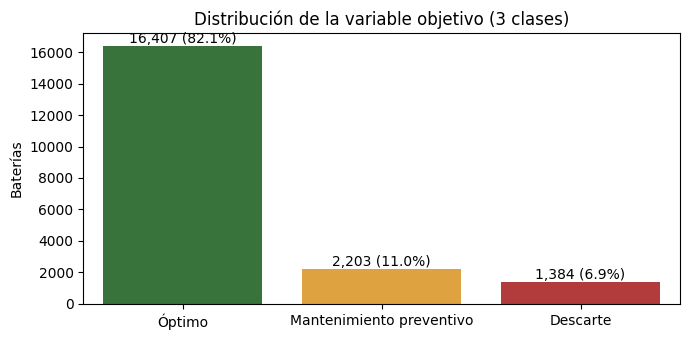

In [7]:
import sys, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sys.path.insert(0, ".")
from src.data import preprocess as pp

df = pd.read_csv(DATA)
pp.verificar_nulos(df)
X, y = pp.preparar_datos(df)
print(f"Registros: {len(df):,} | Variables originales: {df.shape[1]} | Variables de entrada: {X.shape[1]} | Nulos: {int(df.isna().sum().sum())}")

dist = y.map(pp.CLASES).value_counts().reindex(list(pp.CLASES.values()))
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=dist.index, y=dist.values, hue=dist.index, palette=["#2e7d32", "#f9a825", "#c62828"], legend=False, ax=ax)
for i, v in enumerate(dist.values):
    ax.text(i, v, f"{v:,} ({v/len(y):.1%})", ha="center", va="bottom")
ax.set_title("Distribución de la variable objetivo (3 clases)"); ax.set_ylabel("Baterías"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [8]:
!python src/models/train.py --data data/processed/baterias_procesado.csv --output models/

[02:42:45] === 1. CARGA DE DATOS ===
[02:42:45] Registros cargados: 19,994 | Columnas: 70
[02:42:45] Imputacion de nulos con la media: ya aplicada previamente (verificacion: 0 NaN restantes)
[02:42:45] === 2. PREPARACION ===
[02:42:45] Umbral de mantenimiento: vida restante < 6000 ciclos
[02:42:45] Variables excluidas: 15 (identificacion, *_score, vida restante, falla)
[02:42:45] Variables de entrada: 55
[02:42:45]   Clase Óptimo: 16,407 (82.1%)
[02:42:45]   Clase Mantenimiento preventivo: 2,203 (11.0%)
[02:42:45]   Clase Descarte: 1,384 (6.9%)
[02:42:45] === 3. DIVISION TRAIN / TEST (80/20 estratificada, seed=42) ===
[02:42:45] Train: 15,995 registros | Test: 3,999 registros
[02:42:45] Escalado + One-Hot ajustados con Train: 73 features
[02:42:45] === 4. BASELINE: LogisticRegression (multinomial) ===
Fitting 3 folds for each of 8 candidates, totalling 24 fits
[02:42:51] Mejores parametros: {'C': 1, 'class_weight': None} | F1 macro CV = 0.7955
[02:42:51] Baseline -> Test Acc 0.9190 | F

### Paso 3: Matriz de Experimentación

In [9]:
import json
pd.set_option("display.max_colwidth", None, "display.width", 200)
met = json.load(open("models/metricas.json", encoding="utf-8"))

filas = []
for m in met:
    filas.append({
        "Modelo": m["modelo"],
        "Hiperparámetros clave": ", ".join(f"{k}={v}" for k, v in m["hiperparametros"].items()),
        "Accuracy Train": round(m["accuracy_train"], 4),
        "Accuracy Test": round(m["accuracy_test"], 4),
        "F1 macro Train": round(m["f1_macro_train"], 4),
        "F1 macro Test": round(m["f1_macro_test"], 4),
        "Recall Descarte": round(m["recall_descarte"], 4),
        "Recall Mantenimiento": round(m["recall_mantenimiento"], 4),
        "T. entrenamiento (s)": round(m["tiempo_entrenamiento_s"], 2),
        "T. predicción Test (s)": round(m["tiempo_prediccion_test_s"], 4),
        "Diagnóstico": m["diagnostico"],
    })
matriz = pd.DataFrame(filas).set_index("Modelo")
matriz.T

Modelo,LogisticRegression (baseline),XGBoost (principal)
Hiperparámetros clave,"C=1, class_weight=None","subsample=0.7, reg_lambda=5, peso_potencia=0.5, n_estimators=500, min_child_weight=3, max_depth=4, learning_rate=0.03, gamma=0.5, colsample_bytree=0.8, n_estimators_efectivos=465, early_stopping_rounds=30"
Accuracy Train,0.9219,0.9448
Accuracy Test,0.919,0.9135
F1 macro Train,0.8092,0.8913
F1 macro Test,0.7983,0.8099
Recall Descarte,0.7292,0.7978
Recall Mantenimiento,0.6281,0.7574
T. entrenamiento (s),6.32,182.06
T. predicción Test (s),0.0012,0.0485
Diagnóstico,Ajuste adecuado (brecha F1 = 0.011),Sobreajuste moderado (brecha F1 = 0.081)


## Paso 4: Gráficos de rendimiento (matriz de confusión en el *Test Set*)

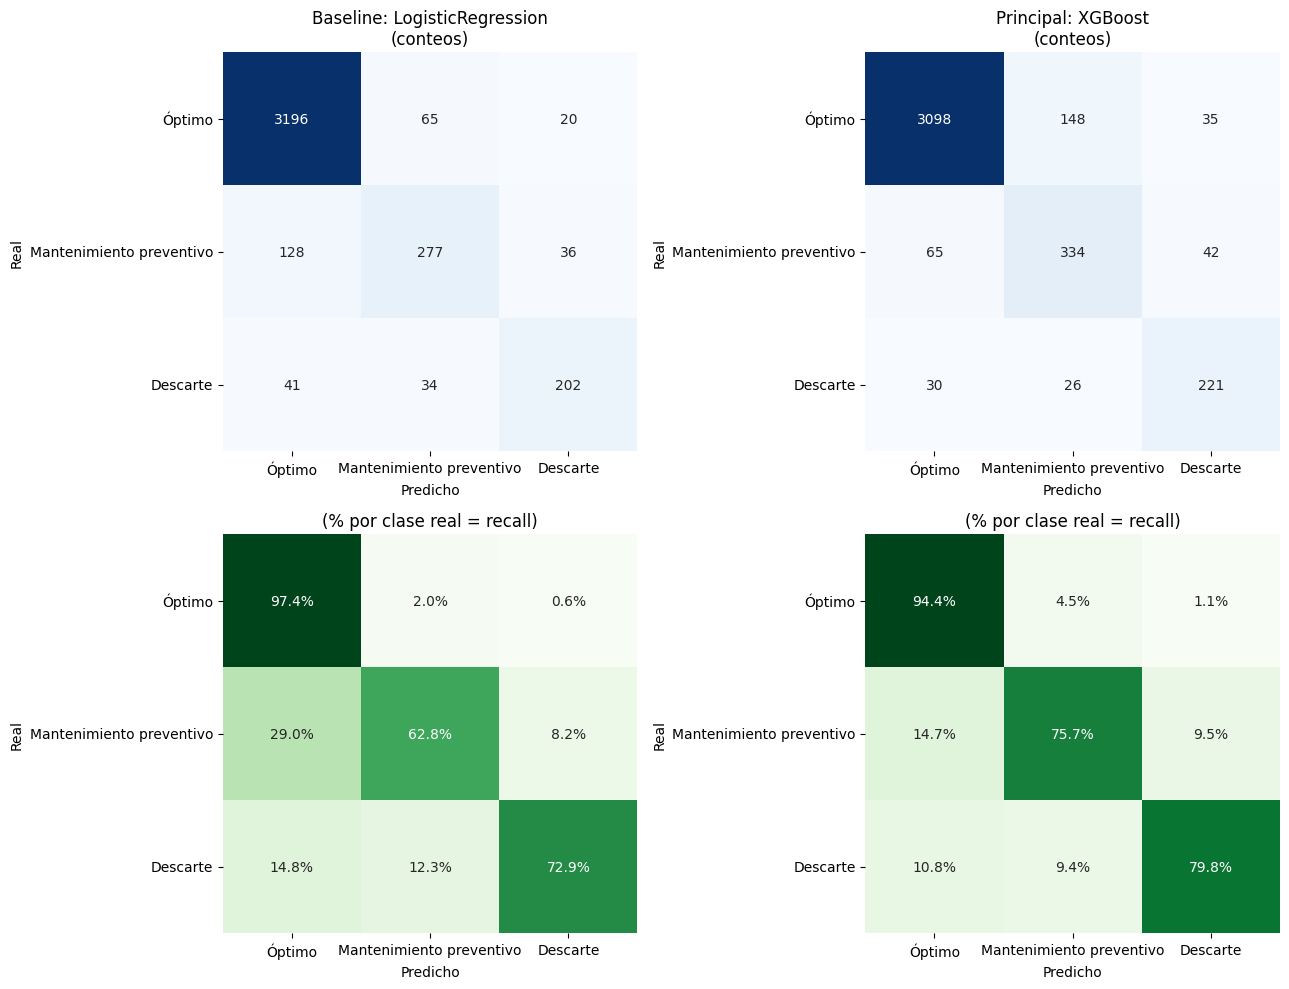

=== XGBoost (principal) en Test Set ===
                          precision    recall  f1-score   support

                  Óptimo     0.9702    0.9442    0.9571      3281
Mantenimiento preventivo     0.6575    0.7574    0.7039       441
                Descarte     0.7416    0.7978    0.7687       277

                accuracy                         0.9135      3999
               macro avg     0.7898    0.8331    0.8099      3999
            weighted avg     0.9199    0.9135    0.9161      3999



In [10]:
import joblib, numpy as np
from sklearn.metrics import confusion_matrix, classification_report

pre = joblib.load("models/preprocessor.joblib")
xgb = joblib.load("models/modelo_baterias.joblib")
base = joblib.load("models/modelo_baseline.joblib")
test = pd.read_csv("data/processed/test_set.csv")
y_te = test.pop("estado_bateria").to_numpy()
Xte = pre.transform(test)
nombres = list(pp.CLASES.values())

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for j, (titulo, modelo) in enumerate([("Baseline: LogisticRegression", base), ("Principal: XGBoost", xgb)]):
    pred = modelo.predict(Xte)
    cm = confusion_matrix(y_te, pred, labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=nombres, yticklabels=nombres, cbar=False, ax=axes[0, j])
    axes[0, j].set_title(f"{titulo}\n(conteos)"); axes[0, j].set_xlabel("Predicho"); axes[0, j].set_ylabel("Real")
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".1%", cmap="Greens", xticklabels=nombres, yticklabels=nombres, cbar=False, ax=axes[1, j])
    axes[1, j].set_title("(% por clase real = recall)"); axes[1, j].set_xlabel("Predicho"); axes[1, j].set_ylabel("Real")
plt.tight_layout(); plt.show()

print("=== XGBoost (principal) en Test Set ===")
print(classification_report(y_te, xgb.predict(Xte), target_names=nombres, digits=4))

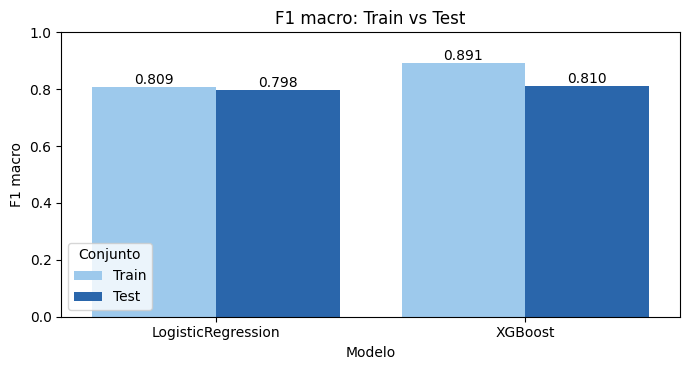

In [11]:
# Train vs Test: diagnóstico visual de sobreajuste
d = pd.DataFrame([{"Modelo": m["modelo"].split(" (")[0], "Conjunto": c, "F1 macro": m[f"f1_macro_{c.lower()}"]}
                  for m in met for c in ["Train", "Test"]])
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.barplot(data=d, x="Modelo", y="F1 macro", hue="Conjunto", palette=["#90caf9", "#1565c0"], ax=ax)
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_ylim(0, 1); ax.set_title("F1 macro: Train vs Test")
plt.tight_layout(); plt.show()

###Explicabilidad global (SHAP): ¿qué variables pesan más en las decisiones del modelo principal?

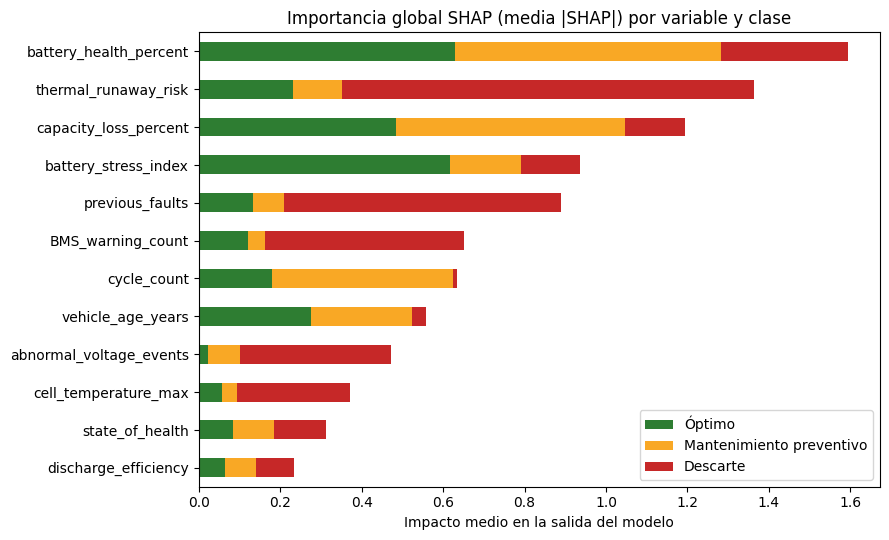

In [12]:
import shap
meta = json.load(open("models/metadata.json", encoding="utf-8"))
muestra_shap = Xte[np.random.RandomState(42).choice(len(Xte), 800, replace=False)]
sv = np.asarray(shap.TreeExplainer(xgb).shap_values(muestra_shap))          # (n, features, clases)
if sv.ndim == 3 and sv.shape[0] != muestra_shap.shape[0]:                    # versiones antiguas de shap
    sv = np.transpose(sv, (1, 2, 0))
imp = np.abs(sv).mean(axis=0)                                                # (features, clases)

def a_variable(nombre):
    return next((c for c in meta["columnas_categoricas"] if nombre.startswith(c + "_")), nombre)

tabla = pd.DataFrame(imp, columns=nombres, index=[a_variable(n) for n in meta["features_transformadas"]]).groupby(level=0).sum()
top = tabla.sum(axis=1).sort_values(ascending=False).head(12).index
tabla.loc[top].iloc[::-1].plot(kind="barh", stacked=True, figsize=(9, 5.5), color=["#2e7d32", "#f9a825", "#c62828"])
plt.title("Importancia global SHAP (media |SHAP|) por variable y clase"); plt.xlabel("Impacto medio en la salida del modelo")
plt.tight_layout(); plt.show()

###Paso 5: Función de inferencia desacoplada con explicabilidad (src/models/predict.py)

In [13]:
import json
from src.models import predict as P

test_real = pd.read_csv("data/processed/test_set.csv")
muestra = test_real[test_real.estado_bateria == 2].iloc[0].drop("estado_bateria").to_dict()   # una batería real (clase Descarte)
print("Entrada (JSON, primeras claves):", json.dumps(dict(list(muestra.items())[:6]), ensure_ascii=False), "...")

resultado = P.predecir(muestra, top_n=5)
print("\nSalida:")
print(json.dumps(resultado, indent=2, ensure_ascii=False))

Entrada (JSON, primeras claves): {"battery_manufacturer": "LG Energy Solution", "battery_chemistry": "LMO", "battery_capacity_kwh": 130.45, "drive_type": "FWD", "odometer_km": 352002.3, "vehicle_age_years": 11.55} ...

Salida:
{
  "clase_predicha": 2,
  "etiqueta": "Descarte",
  "confianza": 0.8829,
  "probabilidades": {
    "Óptimo": 0.0038,
    "Mantenimiento preventivo": 0.1133,
    "Descarte": 0.8829
  },
  "explicacion": [
    {
      "variable": "cell_temperature_max",
      "valor": 65.1,
      "contribucion_shap": 0.8163,
      "impacto_relativo_pct": 21.4,
      "efecto": "empuja hacia 'Descarte'",
      "promedio_flota": 40.41
    },
    {
      "variable": "previous_faults",
      "valor": 2,
      "contribucion_shap": 0.5688,
      "impacto_relativo_pct": 14.9,
      "efecto": "empuja hacia 'Descarte'",
      "promedio_flota": 0.912
    },
    {
      "variable": "battery_health_percent",
      "valor": 54.61,
      "contribucion_shap": 0.5353,
      "impacto_relativo_pct":

###Prueba unitaria

In [14]:
def test_predecir():
    r = P.predecir(muestra, top_n=5)
    claves = {"clase_predicha", "etiqueta", "confianza", "probabilidades", "explicacion", "valor_base_shap", "resumen"}
    assert claves <= set(r), "Faltan claves en la salida"
    assert r["clase_predicha"] in (0, 1, 2)
    assert 0.0 <= r["confianza"] <= 1.0
    assert abs(sum(r["probabilidades"].values()) - 1.0) < 1e-3
    assert len(r["explicacion"]) == 5
    for e in r["explicacion"]:
        assert {"variable", "valor", "contribucion_shap", "impacto_relativo_pct", "efecto"} <= set(e)
    json.dumps(r)                                                            # debe ser serializable a JSON
    assert P.predecir(json.dumps(muestra))["clase_predicha"] == r["clase_predicha"]   # entrada como string JSON

    try:
        P.predecir({"cycle_count": 100})
        raise AssertionError("Debió fallar por variables faltantes")
    except ValueError:
        pass

    assert P.cargar_artefactos.cache_info().misses == 1, "Los artefactos deben cargarse una sola vez"

test_predecir()
print("Prueba unitaria superada: estructura de salida, JSON, validación de entradas y carga única de artefactos.")

# Una batería real de cada clase
filas = []
for k, nombre in pp.CLASES.items():
    m = test_real[test_real.estado_bateria == k].iloc[0].drop("estado_bateria").to_dict()
    r = P.predecir(m)
    filas.append({"Clase real": nombre, "Predicha": r["etiqueta"], "Confianza": r["confianza"],
                  "Variable #1": r["explicacion"][0]["variable"], "Variable #2": r["explicacion"][1]["variable"]})
pd.DataFrame(filas)

Prueba unitaria superada: estructura de salida, JSON, validación de entradas y carga única de artefactos.


,Clase real,Predicha,Confianza,Variable #1,Variable #2
0,Óptimo,Óptimo,0.8000,battery_stress_index,battery_health_percent
1,Mantenimiento preventivo,Mantenimiento preventivo,0.5695,battery_stress_index,capacity_loss_percent
2,Descarte,Descarte,0.8829,cell_temperature_max,previous_faults


### Respuesta a una Bateria fuera del Dataset

#### ¿cómo responde el sistema ante una batería que NO está en el dataset?
#### Cuando llega una batería nueva, el modelo no necesita "haberla visto": aprende
#### patrones (umbrales e interacciones entre variables) y los aplica a cualquier fila
### con las mismas variables. El *Test Set* ya simula eso: 3,999 baterías que el modelo
#### nunca vio durante el entrenamiento.
#### Lo que **sí** cambia en producción es que el usuario no tendrá las 55 variables.
#### `predecir()` exige las 55, así que este apéndice añade una capa por encima
#### (`predecir_nueva`) que:

#### 1. **Valida** la entrada (tipos, rangos vistos en entrenamiento, categorías conocidas).
#### 2. **Exige solo los datos esenciales** y rechaza la consulta si faltan.
#### 3. **Completa** lo que falta: reglas exactas entre variables (p. ej.
####    `capacity_loss_percent = 100 − battery_health_percent`), estimación de los dos
####    índices derivados y, para el resto, la media (numéricas) o la moda (categóricas)
####    del entrenamiento, que es la misma política de imputación del proyecto.
#### 4. **Informa la fiabilidad** de la respuesta según qué tan completa fue la entrada,
####    y marca en la explicación SHAP qué valores fueron reales y cuáles imputados.
#### Los niveles (esencial / recomendada / opcional) no son una opinión: se miden abajo
#### quitando variables y viendo cuánto cae el F1 macro en el Test Set.

In [15]:
# --- 1. Referencias del entrenamiento (medias, modas, rangos) ---------------------
import sys, json, numpy as np, pandas as pd
from sklearn.metrics import f1_score, recall_score
from sklearn.ensemble import HistGradientBoostingRegressor

sys.path.insert(0, ".")
from src.data import preprocess as pp
from src.models import predict as P

_df = pd.read_csv("data/processed/baterias_procesado.csv")
_X, _y = pp.preparar_datos(_df)
_Xtr, _Xte, _ytr, _yte = pp.dividir(_X, _y)          # misma partición del entrenamiento (semilla 42)

_art = P.cargar_artefactos()                         # reutiliza lo ya cargado en memoria
_pre, _modelo, _meta = _art["pre"], _art["modelo"], _art["meta"]

COLS = list(_meta["columnas_entrada"])
CAT = list(_meta["columnas_categoricas"])
NUM = list(_meta["columnas_numericas"])
REF = {c: (_Xtr[c].mode()[0] if c in CAT else float(_Xtr[c].mean())) for c in COLS}
RANGO = {c: (float(_Xtr[c].min()), float(_Xtr[c].max())) for c in NUM}
CATEGORIAS = {c: set(_Xtr[c].unique()) for c in CAT}

# Niveles de datos (justificados con las mediciones de la celda 3)
ESENCIALES = ["thermal_runaway_risk", "previous_faults", "BMS_warning_count", "abnormal_voltage_events"]
GRUPO_SALUD = ["battery_health_percent", "capacity_loss_percent", "state_of_health"]   # basta con UNA
RECOMENDADAS = ["battery_stress_index", "cell_temperature_max", "discharge_efficiency",
                "internal_resistance", "cycle_count", "pack_voltage", "vehicle_age_years"]
INDICES = ["thermal_runaway_risk", "battery_stress_index"]   # índices calculados por el sistema de la batería
RAW_NUM = [c for c in NUM if c not in INDICES]

# Estimadores de los índices a partir de las demás variables (solo se usan si faltan)
_estimadores = {t: HistGradientBoostingRegressor(random_state=pp.SEED).fit(_Xtr[RAW_NUM], _Xtr[t])
                for t in INDICES}
print(f"Referencias listas: {len(COLS)} variables ({len(NUM)} numéricas, {len(CAT)} categóricas).")


# %%
# --- 2. Completado de datos faltantes (vectorizado: sirve para 1 fila o para un lote) -----
def completar(parcial: pd.DataFrame, min_completitud_indices: float = 0.80, inteligente: bool = True):
    """Recibe SOLO las columnas proporcionadas y devuelve el DataFrame con las 55 columnas.

    inteligente=False desactiva reglas y estimaciones (rellena todo con media/moda): sirve para
    medir cuánta información aporta realmente cada dato.
    """
    Z = parcial.copy()
    derivados, estimados = {}, {}

    # a) Reglas entre variables de salud (capacity_loss = 100 - health es EXACTA en el dataset)
    if inteligente and "battery_health_percent" not in Z and "capacity_loss_percent" in Z:
        Z["battery_health_percent"] = 100 - Z["capacity_loss_percent"]
        derivados["battery_health_percent"] = "100 - capacity_loss_percent (exacta)"
    if inteligente and "battery_health_percent" not in Z and "state_of_health" in Z:
        Z["battery_health_percent"] = Z["state_of_health"]
        derivados["battery_health_percent"] = "≈ state_of_health (correlación 0.96)"
    if inteligente and "capacity_loss_percent" not in Z and "battery_health_percent" in Z:
        Z["capacity_loss_percent"] = 100 - Z["battery_health_percent"]
        derivados["capacity_loss_percent"] = "100 - battery_health_percent (exacta)"
    if inteligente and "state_of_health" not in Z and "battery_health_percent" in Z:
        Z["state_of_health"] = Z["battery_health_percent"]
        derivados["state_of_health"] = "≈ battery_health_percent (correlación 0.96)"

    # b) Índices derivados: se estiman solo si hay suficientes variables base
    completitud_raw = sum(c in Z for c in RAW_NUM) / len(RAW_NUM)
    faltan_idx = [t for t in INDICES if t not in Z]
    if inteligente and faltan_idx and completitud_raw >= min_completitud_indices:
        base = pd.DataFrame(index=Z.index)
        for c in RAW_NUM:
            base[c] = Z[c] if c in Z else REF[c]
        for t in faltan_idx:
            Z[t] = _estimadores[t].predict(base)
            estimados[t] = f"estimado desde las demás variables ({completitud_raw:.0%} proporcionadas)"

    # c) Todo lo demás: media (numéricas) o moda (categóricas) del entrenamiento
    imputados = [c for c in COLS if c not in Z]
    for c in imputados:
        Z[c] = REF[c]
    return Z[COLS], {"derivados": derivados, "estimados": estimados, "imputados": imputados}


def f1_escenario(proporcionadas, X=None, y=None, inteligente=True):
    """F1 macro y recall por clase si el usuario solo entregara `proporcionadas` (sobre el Test Set)."""
    X = _Xte if X is None else X
    y = _yte if y is None else y
    Z, _ = completar(X[[c for c in COLS if c in set(proporcionadas)]], inteligente=inteligente)
    pred = _modelo.predict(_pre.transform(Z))
    return f1_score(y, pred, average="macro"), recall_score(y, pred, average=None, labels=[0, 1, 2])


# %%
# --- 3. Medición: ¿qué datos son esenciales y cuáles solo ayudan? -----------------------
# Aquí se mide la información "pura" de cada dato: lo que falta se rellena solo con media/moda
# (inteligente=False), sin reglas ni estimaciones.
completo, _ = f1_escenario(COLS)

# (a) Impacto de quitar UNA variable (el resto se entrega completo)
impacto = pd.Series({c: completo - f1_escenario(set(COLS) - {c}, inteligente=False)[0] for c in COLS}).sort_values(ascending=False)
print("Caída de F1 macro al omitir cada variable (top 12), con las demás completas:")
print(impacto.head(12).round(4).to_string())

# (b) Impacto de quitar GRUPOS redundantes (individualmente cada una "se tapa" con las otras)
print("\nCaída de F1 macro al omitir un grupo completo:")
for nombre, grupo in {"Salud (health, capacity_loss, SoH)": GRUPO_SALUD,
                      "Fallas (previas, BMS, voltaje anómalo)": ["previous_faults", "BMS_warning_count", "abnormal_voltage_events"],
                      "Índices (thermal_runaway, stress)": INDICES}.items():
    f, _ = f1_escenario(set(COLS) - set(grupo), inteligente=False)
    print(f"  {nombre:<42} -{completo - f:.4f}")

# (c) Escenarios de entrega de datos: solo con media vs. con las reglas/estimaciones del sistema
esc = {
    "Completo (55 variables)": COLS,
    "Esenciales + 1 de salud (5)": ESENCIALES + ["battery_health_percent"],
    "Esenciales + recomendadas (12)": ESENCIALES + ["battery_health_percent"] + RECOMENDADAS,
    "Todo excepto los 2 índices (53)": [c for c in COLS if c not in INDICES],
}
filas = []
for nombre, cols in esc.items():
    f_media, _ = f1_escenario(cols, inteligente=False)
    f, r = f1_escenario(cols)
    filas.append({"Escenario": nombre, "F1 solo media": round(f_media, 4), "F1 con reglas+estimación": round(f, 4),
                  "% del completo": f"{f / completo:.1%}", "Recall Óptimo": round(r[0], 3),
                  "Recall Mantenim.": round(r[1], 3), "Recall Descarte": round(r[2], 3)})
pd.DataFrame(filas).set_index("Escenario")


# %%
# --- 4. Niveles de fiabilidad: esenciales + k recomendadas (promedio de 10 sorteos) ------
rng = np.random.RandomState(0)
base_ese = ESENCIALES + ["battery_health_percent"]
curva = []
for k in range(len(RECOMENDADAS) + 1):
    vals = [f1_escenario(base_ese + list(rng.choice(RECOMENDADAS, k, replace=False)))[0] for _ in range(10 if 0 < k < len(RECOMENDADAS) else 1)]
    curva.append({"Recomendadas entregadas": f"{k} de {len(RECOMENDADAS)}", "F1 macro (prom.)": round(float(np.mean(vals)), 4),
                  "% del completo": f"{np.mean(vals) / completo:.1%}"})
pd.DataFrame(curva).set_index("Recomendadas entregadas")


# %%
# --- 5. Función de inferencia para baterías nuevas ---------------------------------------
def _es_nulo(v):
    return v is None or (isinstance(v, float) and np.isnan(v)) or (isinstance(v, str) and v.strip() == "")


def _nivel_fiabilidad(n_rec: int) -> str:
    if n_rec >= 6:
        return "Alta"
    if n_rec >= 3:
        return "Media"
    return "Baja (orientativa)"


def predecir_nueva(muestra, top_n: int = 5) -> dict:
    """Predice una batería nueva aunque falten variables NO esenciales.

    muestra : dict o string JSON. Puede traer claves extra (se ignoran) y nulos (se tratan como faltantes).
    Lanza ValueError si faltan datos esenciales o hay valores no numéricos.
    """
    if isinstance(muestra, str):
        muestra = json.loads(muestra)
    if not isinstance(muestra, dict):
        raise TypeError("La muestra debe ser un dict o un string JSON.")

    dado = {c: muestra[c] for c in COLS if c in muestra and not _es_nulo(muestra[c])}
    advertencias = []

    for c in NUM:                                            # tipos y rangos
        if c in dado:
            try:
                dado[c] = float(dado[c])
            except (TypeError, ValueError):
                raise ValueError(f"'{c}' debe ser numérico; se recibió {dado[c]!r}.")
            lo, hi = RANGO[c]
            if not lo <= dado[c] <= hi:
                advertencias.append(f"{c}={dado[c]} está fuera del rango de entrenamiento [{lo:.4g}, {hi:.4g}]: "
                                    f"el modelo extrapola y la predicción es menos fiable.")
    for c in CAT:                                            # categorías desconocidas
        if c in dado and dado[c] not in CATEGORIAS[c]:
            advertencias.append(f"{c}='{dado[c]}' no existía en el entrenamiento (valores conocidos: "
                                f"{sorted(CATEGORIAS[c])}); se trata como categoría desconocida.")

    Z, info = completar(pd.DataFrame([dado]))

    faltan = [c for c in ESENCIALES if c not in dado and c not in info["estimados"]]
    if not any(c in dado for c in GRUPO_SALUD):
        faltan.append("battery_health_percent (o capacity_loss_percent, o state_of_health)")
    if faltan:
        raise ValueError(f"Faltan datos esenciales para responder: {faltan}")

    r = P.predecir(Z.iloc[0].to_dict(), top_n=top_n)         # reutiliza la función ya validada

    for e in r["explicacion"]:                               # trazabilidad: ¿dato real o rellenado?
        v = e["variable"]
        e["origen"] = ("proporcionado" if v in dado else "derivado" if v in info["derivados"]
                       else "estimado" if v in info["estimados"] else "imputado (media/moda)")

    rec_dadas = [c for c in RECOMENDADAS if c in dado or c in info["estimados"]]
    nivel = _nivel_fiabilidad(len(rec_dadas))
    r.update({
        "fiabilidad": nivel,
        "completitud": round(len(dado) / len(COLS), 3),
        "campos_proporcionados": len(dado),
        "campos_derivados": info["derivados"],
        "campos_estimados": info["estimados"],
        "campos_imputados": len(info["imputados"]),
        "recomendados_faltantes": [c for c in RECOMENDADAS if c not in rec_dadas],
        "advertencias": advertencias,
    })
    if nivel.startswith("Baja"):
        r["resumen"] += " ⚠ Respuesta orientativa: entregue más variables recomendadas para mejorarla."
    return r


# %%
# --- 6. Formulario sugerido para el Dashboard (qué pedir y con qué rango) ------------------
desc = {
    "thermal_runaway_risk": "Índice de riesgo de fuga térmica (0–100)",
    "previous_faults": "Número de fallas previas registradas",
    "BMS_warning_count": "Número de advertencias del BMS",
    "abnormal_voltage_events": "Eventos de voltaje anómalo",
    "battery_health_percent": "Salud de la batería (%). Alternativas: capacity_loss_percent o state_of_health",
    "battery_stress_index": "Índice de estrés de la batería",
    "cell_temperature_max": "Temperatura máxima de celda",
    "discharge_efficiency": "Eficiencia de descarga (%)",
    "internal_resistance": "Resistencia interna",
    "cycle_count": "Ciclos de carga acumulados",
    "pack_voltage": "Voltaje del pack",
    "vehicle_age_years": "Antigüedad (años)",
}
orden = ESENCIALES + ["battery_health_percent"] + RECOMENDADAS
formulario = pd.DataFrame({
    "Nivel": ["Esencial"] * 5 + ["Recomendada"] * len(RECOMENDADAS),
    "Descripción": [desc[c] for c in orden],
    "Mín. entrenamiento": [round(RANGO[c][0], 2) for c in orden],
    "Máx. entrenamiento": [round(RANGO[c][1], 2) for c in orden],
}, index=orden)
print("Las 43 variables restantes son OPCIONALES: no aportan mejora medible (ver celda 3).")
print("Unidades: las mismas del dataset original; confirmar con su diccionario de datos.")
formulario


# %%
# --- 7. Pruebas ---------------------------------------------------------------------------
_fila = _Xte.iloc[0].to_dict()                     # una batería real del Test Set
_real = int(_yte.iloc[0])

# (a) Entrada completa: debe coincidir con predecir() directo
r_full = predecir_nueva(_fila)
r_dir = P.predecir(_fila)
assert r_full["clase_predicha"] == r_dir["clase_predicha"] and abs(r_full["confianza"] - r_dir["confianza"]) < 1e-6
assert r_full["fiabilidad"] == "Alta" and r_full["campos_imputados"] == 0

# (b) Solo 12 variables (esenciales + recomendadas): responde y avisa qué rellenó
_doce = {c: _fila[c] for c in ESENCIALES + ["battery_health_percent"] + RECOMENDADAS}
r12 = predecir_nueva(_doce)
assert r12["fiabilidad"] == "Alta" and r12["campos_proporcionados"] == 12
assert "capacity_loss_percent" in r12["campos_derivados"]

# (c) Solo los 5 esenciales: responde pero con fiabilidad baja
r5 = predecir_nueva({c: _fila[c] for c in ESENCIALES + ["battery_health_percent"]})
assert r5["fiabilidad"].startswith("Baja") and len(r5["recomendados_faltantes"]) == len(RECOMENDADAS)

# (d) Falta un esencial -> debe rechazar
try:
    predecir_nueva({c: _fila[c] for c in COLS if c != "previous_faults"})
    raise AssertionError("Debió rechazar la consulta")
except ValueError as e:
    assert "previous_faults" in str(e)

# (e) Sin ningún dato de salud -> debe rechazar
try:
    predecir_nueva({c: _fila[c] for c in COLS if c not in GRUPO_SALUD})
    raise AssertionError("Debió rechazar la consulta")
except ValueError:
    pass

# (f) Valor fuera de rango, categoría nueva y texto no numérico
r_out = predecir_nueva({**_fila, "cycle_count": 99999, "battery_chemistry": "Sodio-ion"})
assert len(r_out["advertencias"]) == 2
try:
    predecir_nueva({**_fila, "cycle_count": "muchos"})
    raise AssertionError("Debió rechazar el texto")
except ValueError:
    pass

# (g) Acepta JSON como string y nulos como faltantes
r_json = predecir_nueva(json.dumps({**_doce, "odometer_km": None, "id_extra": "ignorada"}))
assert r_json["campos_proporcionados"] == 12
json.dumps(r_json, default=str)                                # salida serializable
print("Todas las pruebas del apéndice superadas.")

print(f"\nBatería real (clase {pp.CLASES[_real]}) con solo 12 variables:")
print(json.dumps({k: r12[k] for k in ["etiqueta", "confianza", "fiabilidad", "completitud", "campos_derivados",
                                      "campos_estimados", "recomendados_faltantes", "advertencias"]},
                 indent=2, ensure_ascii=False))
pd.DataFrame(r12["explicacion"])[["variable", "valor", "origen", "contribucion_shap", "impacto_relativo_pct"]]

Referencias listas: 55 variables (50 numéricas, 5 categóricas).
Caída de F1 macro al omitir cada variable (top 12), con las demás completas:
thermal_runaway_risk       0.1002
previous_faults            0.0956
battery_health_percent     0.0656
capacity_loss_percent      0.0547
BMS_warning_count          0.0496
abnormal_voltage_events    0.0203
battery_stress_index       0.0099
cell_temperature_max       0.0071
pack_voltage               0.0037
discharge_efficiency       0.0035
cycle_count                0.0031
internal_resistance        0.0028

Caída de F1 macro al omitir un grupo completo:
  Salud (health, capacity_loss, SoH)         -0.2194
  Fallas (previas, BMS, voltaje anómalo)     -0.1543
  Índices (thermal_runaway, stress)          -0.1136
Las 43 variables restantes son OPCIONALES: no aportan mejora medible (ver celda 3).
Unidades: las mismas del dataset original; confirmar con su diccionario de datos.
Todas las pruebas del apéndice superadas.

Batería real (clase Óptimo) con sol

,variable,valor,origen,contribucion_shap,impacto_relativo_pct
0,battery_stress_index,64.52,proporcionado,-0.8515,30.0
1,battery_health_percent,81.07,proporcionado,0.5137,18.1
2,capacity_loss_percent,18.93,derivado,0.4378,15.4
3,vehicle_age_years,6.87,proporcionado,0.1250,4.4
4,thermal_runaway_risk,25.27,proporcionado,0.1215,4.3
